# MRI Safety

**Part:** B – The MRI system (hardware & engineering) · **Reading time:** ~60 min · **Pass 1 overview:** [Speed, artifacts and safety](../pass1_big_picture/P1.5_Speed_Artifacts_and_Safety.ipynb) · **Refreshers you may want:** [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb), [Induction & RF](../refreshers/RP2_Induction_and_RF.ipynb)

MRI uses no ionizing radiation, but it does expose the patient (and staff) to three strong physical fields at once: a **static field** $B_0$ of several tesla, **time-varying gradient fields** switching thousands of times per second, and **RF fields** at tens to hundreds of MHz. Each field brings its own hazards. A fourth group comes from the hardware itself: cryogens, acoustic noise, and the contrast agents injected into the patient.

**Why this chapter matters.** Safety limits are not a footnote; they are a hard engineering constraint that shapes almost every sequence. SAR limits how fast you can run spin echoes at 3 T, nerve stimulation caps the gradient slew rate, and the projectile risk dictates the architecture of the whole MRI suite. This chapter explains *where each hazard comes from physically*, estimates its size with simple models, and states the regulatory limits.

> **⚠️ Common confusion:** The numbers in this chapter are for understanding, not for clinical decisions. Real limits come from the current edition of IEC 60601-2-33, the scanner's own monitoring, and each implant's manufacturer labeling.

## Learning goals

1. Explain the physical origin of each MRI hazard: static field, gradient switching, RF heating, acoustic noise, cryogens, and contrast agents.
2. Estimate the translational force on a ferromagnetic object from $B\,\partial B/\partial z$, and explain why the danger peaks near the bore entrance, not at the centre.
3. Compute $dB/dt$ seen by the body from the slew rate, and use the rheobase–chronaxie model of nerve stimulation.
4. Derive a simple model of SAR ($\sigma |E|^2/\rho$), and explain why SAR scales with $B_0^2$, $\theta^2$ and $1/T_{rf}$.
5. Explain implant heating (antenna effect), the MR Safe / MR Conditional / MR Unsafe labels, and the zone concept of an MRI suite.
6. Know the order of magnitude of the main regulatory limits (SAR, temperature, dB/dt, noise).

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $B_0$ | main static field | T | 1.5, 3, 7 T |
| $B(z)$ | static field magnitude along the bore axis, inside and outside the magnet | T | falls from $B_0$ to ~0 within a few metres |
| $\partial B/\partial z$ | **spatial field gradient** of the static field (not the imaging gradient!) | T/m | up to several T/m near the bore entrance |
| $\vec F$, $F_z$ | force on an object; its component along the bore | N | |
| $V$, $m$, $\rho_m$ | volume, mass and density of an object | m³, kg, kg/m³ | steel ≈ 7800 kg/m³ |
| $\chi$ | magnetic susceptibility (dimensionless, SI) | – | steel: ≫ 1 (ferromagnetic) |
| $M_s$ | saturation magnetization of a ferromagnet | A/m | soft iron ≈ 1.7×10⁶ A/m |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $g$ | gravitational acceleration | m/s² | 9.81 |
| $G$, $SR$ | imaging gradient amplitude; slew rate $dG/dt$ | T/m, T/m/s | 40 mT/m, 200 T/m/s |
| $r$ | distance from the gradient isocentre | m | body edge ≈ 0.2–0.3 m |
| $dB/dt$ | rate of change of the field seen by tissue | T/s | tens of T/s |
| $\tau_s$ | stimulus duration (here: gradient ramp time) | s | 0.1–1 ms |
| $b$, $c$ | **rheobase** (threshold for very long stimuli) and **chronaxie** (duration at which the threshold doubles) | T/s, s | ~20 T/s, ~0.36 ms (IEC model; see text) |
| $\vec E$ | electric field induced in tissue | V/m | |
| $\sigma_{el}$ | electrical conductivity of tissue | S/m | ~0.5–0.9 S/m (muscle, MHz range) |
| $\rho$ | tissue mass density | kg/m³ | ≈ 1000 |
| $SAR$ | **specific absorption rate**: RF power absorbed per kg of tissue | W/kg | limits 2–4 W/kg whole body |
| $B_1$, $B_{1,rms}$ | RF field amplitude; its root-mean-square value over time | T | µT |
| $\omega_0=2\pi f_0$ | Larmor angular frequency | rad/s | $2\pi\times127.7$ MHz at 3 T |
| $\theta$, $T_{rf}$, $TR$ | flip angle; RF pulse duration; repetition time | rad, s, s | |
| $R_{body}$ | radius of a cylinder modelling the body | m | 0.15–0.2 m |
| $c_{tissue}$ | specific heat capacity of tissue | J/(kg K) | ≈ 3500 |
| $\Delta T$ | temperature rise | K (= °C difference) | |
| $\lambda$, $\varepsilon_r$ | RF wavelength; relative permittivity of tissue | m, – | $\varepsilon_r$ ≈ 50–80 |
| $L_{res}$ | resonant length of a wire implant ≈ $\lambda/2$ in tissue | m | 10–30 cm |
| $p$, $SPL$ | sound pressure; sound pressure level $20\log_{10}(p/20\,\mu\text{Pa})$ | Pa, dB | MRI: 80–120 dB(A) |
| $I_c$, $\ell$ | current in a gradient wire; wire length | A, m | hundreds of A |

> **⚠️ Common confusion:** Two very different "gradients" appear here. The **imaging gradient** $G$ (T/m) is the deliberately switched field of the gradient coils. The **spatial field gradient** $\partial B/\partial z$ of the *static* magnet is its fringe-field fall-off. The second one pulls ferromagnetic objects into the magnet.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Overview: four fields, four groups of hazards

| Source | Physical effect | Main hazards | Main safeguards |
|---|---|---|---|
| **Static field** $B_0$ (always on!) | force and torque on magnetic materials; induced currents in moving conductors | projectiles, implant movement, vertigo | screening, zones, MR Conditional labels |
| **Gradient switching** $dG/dt$ | Faraday induction of electric fields in tissue; Lorentz forces on coil wires | peripheral nerve stimulation (PNS), acoustic noise | dB/dt limits, hearing protection |
| **RF field** $B_1$ | induced currents in tissue ⇒ resistive heating; antenna effect in leads | whole-body and local heating, burns | SAR limits, positioning, implant conditions |
| **Hardware & drugs** | liquid helium; contrast agents | asphyxiation after a quench; reactions, NSF, gadolinium retention | quench pipe and O₂ monitor; agent choice |

> **🔧 Engineering reality:** The static field of a superconducting magnet is **always on**, even at night and during a power cut (see [B3 Main magnet engineering](B3_Main_Magnet_Engineering.ipynb)). Most serious accidents happen when someone forgets this, not during the scan itself.

## 2. The static field: projectiles and torque

### 2.1 Why a uniform field does not pull, but a fringe field does

A small magnetic object with magnetic moment $\vec m_{mag}$ (in A m², the "strength" of the magnet the object becomes) has potential energy $U=-\vec m_{mag}\cdot\vec B$. A force appears only where this energy *changes with position*:

$$F_z = -\frac{\partial U}{\partial z} = m_{mag}\,\frac{\partial B}{\partial z}$$

**In words:** an object is pulled toward stronger field, and the pull is proportional to how fast the field *changes* along the way. In the perfectly uniform centre of the magnet $\partial B/\partial z = 0$, so there is **no net pull**, only torque. The fringe field near the bore entrance is where the field rises steeply.

For a **ferromagnetic** object (steel, iron, nickel), the moment itself grows with the field:

* **Unsaturated** (weak field): a soft-iron sphere has $m_{mag} \approx 3VB/\mu_0$. The factor 3 comes from the sphere's shape ("demagnetization"). Then
  $$F_z \approx \frac{3V}{\mu_0}\,B\,\frac{\partial B}{\partial z}$$
* **Saturated** (above roughly 1–2 T for iron): the moment cannot grow any more, $m_{mag}=M_sV$, and
  $$F_z = M_s V\,\frac{\partial B}{\partial z}$$

where $V$ is the object's volume, $\mu_0$ the vacuum permeability and $M_s$ the saturation magnetization.

**In words:** in the fringe field, the danger scales with the **product** $B\,\partial B/\partial z$ (unsaturated) or with $\partial B/\partial z$ alone (saturated). Both peak near the bore entrance.

Let's estimate this for a 3 T magnet. As a toy model we use a 1.6 m long solenoid (approximated by 40 current loops) of radius 0.45 m, scaled so that $B=3$ T at the centre. Real, actively shielded magnets have a much shorter fringe field (see B3), so this is a pessimistic but instructive model.

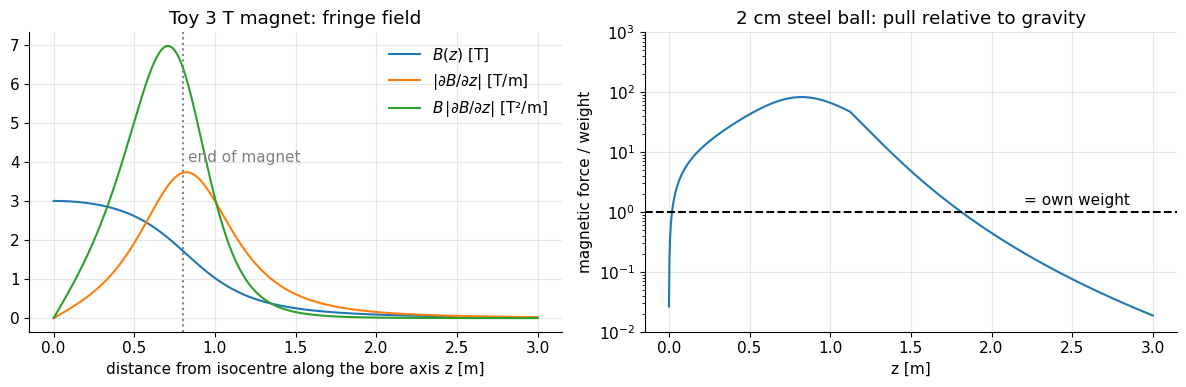

steel ball mass 33 g; max force 27 N = 83 x its weight at z = 0.82 m (B = 1.64 T, dB/dz = 3.7 T/m)
at the isocentre: dB/dz = 1.2e-03 T/m  ->  essentially no pull


In [2]:
# Toy magnet: 40 loops along z, radius 0.45 m, total length 1.6 m, scaled to 3 T at the centre
R_mag, L_mag, n_loops, B0 = 0.45, 1.6, 40, 3.0
z_loops = np.linspace(-L_mag / 2, L_mag / 2, n_loops)
z = np.linspace(0, 3.0, 3001)                       # metres from isocentre along the axis
B = sum(mt.loop_field_on_axis(z - zl, R_mag, 1.0) for zl in z_loops)
B *= B0 / B[0]                                      # scale: B(0) = 3 T
dBdz = np.gradient(B, z)

# Force on a soft-steel sphere of 2 cm diameter (e.g. a big ball bearing)
d = 0.02; V = np.pi / 6 * d**3; rho_steel = 7800; m = rho_steel * V; g = 9.81
Ms = 1.7e6                                          # A/m, saturation magnetization of soft iron
F_unsat = 3 * V / mt.MU0 * B * np.abs(dBdz)
F_sat = Ms * V * np.abs(dBdz)
F = np.minimum(F_unsat, F_sat)                      # the moment cannot exceed saturation

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(z, B, label=r"$B(z)$ [T]")
ax[0].plot(z, np.abs(dBdz), label=r"$|\partial B/\partial z|$ [T/m]")
ax[0].plot(z, B * np.abs(dBdz), label=r"$B\,|\partial B/\partial z|$ [T²/m]")
ax[0].axvline(L_mag / 2, color="gray", ls=":"); ax[0].text(L_mag / 2 + 0.03, 4, "end of magnet", color="gray")
ax[0].set_xlabel("distance from isocentre along the bore axis z [m]"); ax[0].legend(); ax[0].set_title("Toy 3 T magnet: fringe field")
ax[1].semilogy(z, F / (m * g))
ax[1].axhline(1, color="k", ls="--"); ax[1].text(2.2, 1.3, "= own weight")
ax[1].set_xlabel("z [m]"); ax[1].set_ylabel("magnetic force / weight")
ax[1].set_title("2 cm steel ball: pull relative to gravity"); ax[1].set_ylim(1e-2, 1e3)
plt.tight_layout(); plt.show()
i = np.argmax(F)
print(f"steel ball mass {m*1e3:.0f} g; max force {F[i]:.0f} N = {F[i]/(m*g):.0f} x its weight at z = {z[i]:.2f} m "
      f"(B = {B[i]:.2f} T, dB/dz = {abs(dBdz[i]):.1f} T/m)")
print(f"at the isocentre: dB/dz = {abs(dBdz[0]):.1e} T/m  ->  essentially no pull")

**Interpretation.** The pull is negligible a few metres away, but it rises **by orders of magnitude over less than a metre**: in our toy model the force becomes tens of times the object's weight near the end of the magnet. That is why a pair of scissors, an oxygen cylinder or a floor polisher "jumps" into the bore, reaching speeds of many metres per second. Note that the force is also zero at the very centre: the object is accelerated *toward* the centre and passes through it.

> **🔧 Engineering reality:** Implant labels state a maximum **spatial field gradient** (for example "≤ 3 T/m") in addition to $B_0$. You will find the scanner's spatial-gradient map in its documentation. The highest values occur near the bore opening, where the patient's body actually passes through.

### 2.2 Torque

An elongated ferromagnetic object (clip, needle) in a *uniform* field feels no net force but a **torque** that tries to align its long axis with $\vec B$: $\vec\tau = \vec m_{mag}\times\vec B$. Inside the bore the torque is maximal. Old ferromagnetic aneurysm clips have been twisted in this way, with fatal consequences; this is why modern clips are made of non-ferromagnetic alloys (titanium etc.).

### 2.3 Biological effects of the static field itself

No harmful long-term effects of static fields up to the clinical range have been established. Short-term effects at high fields (especially when moving quickly in the fringe field of a 7 T magnet) include **vertigo**, nausea, a **metallic taste** and light flashes (magnetophosphenes). They are caused by currents induced in the inner ear and other tissues by motion through $\partial B/\partial z$. The **magnetohydrodynamic effect**, a voltage induced by blood flowing through $B_0$, distorts the ECG (elevated T wave) inside the bore, which is why cardiac gating and patient monitoring need MR-specific electronics.

➡️ **Go deeper:** magnet construction and fringe-field shielding in [B3 Main magnet engineering](B3_Main_Magnet_Engineering.ipynb).

## 3. Gradient switching: nerve stimulation

### 3.1 How large is dB/dt in the body?

A gradient adds the field $B_z = G\,x$ (for an x-gradient). When the gradient ramps up at slew rate $SR = dG/dt$, a tissue point at distance $r$ from the isocentre sees

$$\frac{dB}{dt} = SR\cdot r$$

**In words:** $dB/dt$ is zero at the centre and grows linearly toward the edge of the coil's field. Where it is largest (shoulders, back, nose, at the end of the linear region) nerves are stimulated first. By Faraday's law (see [RP2](../refreshers/RP2_Induction_and_RF.ipynb)) this changing flux induces an electric field in the tissue, roughly $E\approx \tfrac{1}{2}\,r_{loop}\,dB/dt$ for a conducting loop of radius $r_{loop}$. If $E$ is large enough, it depolarizes peripheral nerves: the patient feels tingling or twitching (**peripheral nerve stimulation, PNS**).

### 3.2 The rheobase–chronaxie model

Nerve excitation needs a certain *charge*, so short stimuli need higher $dB/dt$. The classic **hyperbolic strength–duration model** (Weiss/Lapicque) is

$$\left(\frac{dB}{dt}\right)_{threshold} = b\left(1 + \frac{c}{\tau_s}\right)$$

where $\tau_s$ is the stimulus duration (the ramp time of the gradient), $b$ is the **rheobase** (the threshold for very long stimuli) and $c$ the **chronaxie** (the duration at which the threshold is twice the rheobase).

**In words:** fast ramps ($\tau_s \ll c$) can tolerate a much higher $dB/dt$ than slow ones. IEC 60601-2-33 uses this form for whole-body gradient systems, with values close to $b\approx 20$ T/s and $c\approx 0.36$ ms. The "normal operating mode" allows 80 % of this threshold curve, the "first level controlled mode" 100 %.

> **TODO (polish):** Verify the exact IEC 60601-2-33 rheobase/chronaxie constants and the definition of the effective stimulus duration in the current edition, and add the cardiac stimulation limit.

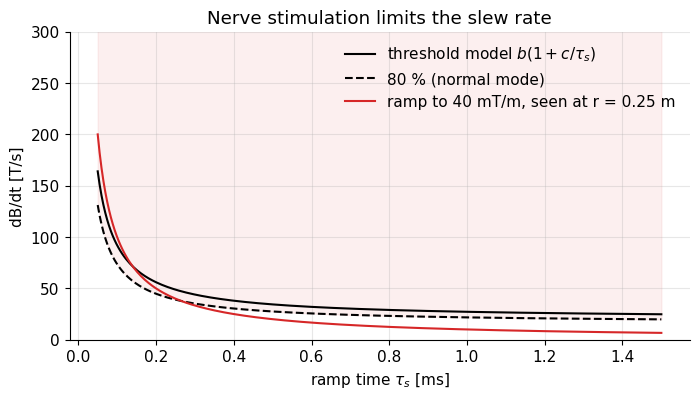

shortest allowed ramp to 40 mT/m (normal mode): 268 us -> max usable slew rate ~ 149 T/m/s


In [3]:
# PNS: dB/dt seen at the body edge vs. the stimulation threshold
b_rheo, c_chron = 20.0, 0.36e-3          # T/s, s  (approximate IEC-type model, see TODO above)
r_edge = 0.25                            # m, distance from isocentre to the body edge
G_max = 40e-3                            # T/m

tau = np.linspace(0.05e-3, 1.5e-3, 300)                     # ramp time [s]
threshold = b_rheo * (1 + c_chron / tau)
dBdt_needed = (G_max / tau) * r_edge                        # SR = G/tau, dB/dt = SR * r

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tau * 1e3, threshold, "k", label="threshold model $b(1+c/\\tau_s)$")
ax.plot(tau * 1e3, 0.8 * threshold, "k--", label="80 % (normal mode)")
ax.plot(tau * 1e3, dBdt_needed, "C3", label=f"ramp to {G_max*1e3:.0f} mT/m, seen at r = {r_edge} m")
ax.fill_between(tau * 1e3, 0.8 * threshold, 400, color="C3", alpha=0.07)
ax.set_ylim(0, 300); ax.set_xlabel(r"ramp time $\tau_s$ [ms]"); ax.set_ylabel("dB/dt [T/s]")
ax.set_title("Nerve stimulation limits the slew rate"); ax.legend(); plt.show()

ok = dBdt_needed <= 0.8 * threshold
tau_min = tau[ok][0]
print(f"shortest allowed ramp to {G_max*1e3:.0f} mT/m (normal mode): {tau_min*1e6:.0f} us "
      f"-> max usable slew rate ~ {G_max/tau_min:.0f} T/m/s")

**Interpretation.** The red curve shows the $dB/dt$ needed for faster and faster ramps. Where it enters the shaded region, the patient would be stimulated. With these numbers, the usable slew rate is limited to about 150–200 T/m/s, which is where clinical gradient specs sit. The **amplifier could deliver more; the human body is the limit.** This is why high-performance gradients are built as small, short head-only coils: a shorter linear region (smaller $r$ at which large fields occur) allows higher slew rates before PNS.

> **🔧 Engineering reality:** Scanners predict PNS for every sequence before it runs (a "PNS monitor" based on the gradient coil's measured stimulation model) and stretch ramps or reduce the gradient amplitude if needed. EPI and diffusion sequences are usually the ones that hit this limit. Cardiac stimulation needs about an order of magnitude higher dB/dt and longer stimuli, so PNS is reached long before it.

➡️ **Go deeper:** gradient amplifiers and slew rate in [B4 Gradient system engineering](B4_Gradient_System_Engineering.ipynb).

## 4. RF heating and SAR

### 4.1 Where the heat comes from

The RF field $B_1$ oscillates at the Larmor frequency $f_0$. By Faraday's law it induces an oscillating **electric field** $\vec E$ in the conductive body, which drives currents and dissipates energy, exactly like a microwave oven (but at lower frequency). The power absorbed per kilogram is the **specific absorption rate**:

$$SAR = \frac{\sigma_{el}\,|\vec E_{rms}|^2}{\rho}$$

where $\sigma_{el}$ is the tissue conductivity, $\vec E_{rms}$ the root-mean-square electric field and $\rho$ the tissue density.

<details><summary><b>📐 Derivation (optional): SAR of a uniform cylinder in a uniform B1 field</b></summary>

Model the body as a long homogeneous cylinder of radius $R_{body}$ in a uniform field $B_1\cos(\omega_0 t)$ along the cylinder axis (a linearly polarized, quasi-static approximation). Faraday's law around a circle of radius $r$ inside the cylinder:

$$\oint \vec E\cdot d\vec l = -\frac{d\Phi}{dt} \quad\Rightarrow\quad E(r)\,2\pi r = \omega_0 B_1 \pi r^2 \sin(\omega_0 t)$$

so the amplitude is $E(r) = \tfrac12\,\omega_0 B_1\,r$: zero at the centre, largest at the surface. With $E_{rms}^2 = \tfrac12 E^2$ for a sinusoid (or simply using $B_{1,rms}$ in place of the amplitude), the local SAR is

$$SAR(r) = \frac{\sigma_{el}}{\rho}\,\frac{\omega_0^2 B_{1,rms}^2 r^2}{4}$$

Averaging over the cross-section, $\langle r^2\rangle = R_{body}^2/2$:

$$\overline{SAR} = \frac{\sigma_{el}\,\omega_0^2\,B_{1,rms}^2\,R_{body}^2}{8\rho}$$

</details>

**In words**, the model gives the three famous scaling laws:

* $SAR \propto \omega_0^2 \propto B_0^2$: **going from 1.5 T to 3 T multiplies SAR by four** for the same flip angles. (At high fields, $\sigma_{el}$ rises and the quasi-static model breaks down. Real SAR grows somewhat more slowly than $B_0^2$, but the trend holds.)
* $SAR \propto B_{1,rms}^2$, and since the flip angle is $\theta = \gamma B_1 T_{rf}$: $SAR \propto \theta^2/T_{rf}$ per pulse, times the number of pulses per second. A 180° pulse costs **4×** the SAR of a 90° pulse of the same duration.
* $SAR \propto R_{body}^2$: larger patients absorb more per kg, and heating is concentrated at the **surface** (where $E$ is largest).

TSE, refocusing 180°: B1rms = 1.50 uT  ->  SAR ~ 0.65 W/kg at 1.5 T, 2.61 W/kg at 3 T
TSE, refocusing 150°: B1rms = 1.25 uT  ->  SAR ~ 0.46 W/kg at 1.5 T, 1.82 W/kg at 3 T
TSE, refocusing 120°: B1rms = 1.01 uT  ->  SAR ~ 0.30 W/kg at 1.5 T, 1.18 W/kg at 3 T


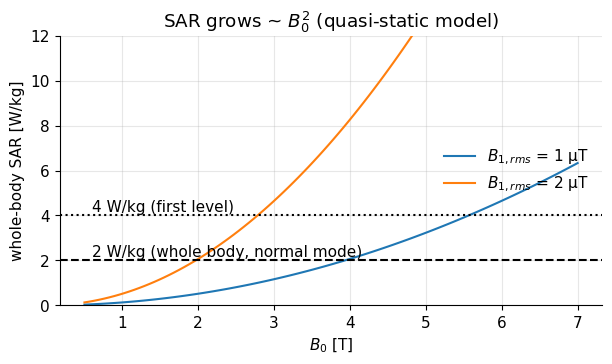

In [4]:
# Quasi-static cylinder model of whole-body SAR (illustrative)
sigma_el, rho, R_body = 0.5, 1000.0, 0.17     # S/m, kg/m^3, m

def sar_cylinder(B1rms, B0):
    w0 = 2 * np.pi * mt.larmor_frequency(B0)
    return sigma_el * w0**2 * B1rms**2 * R_body**2 / (8 * rho)

def b1rms_sequence(theta_list, T_rf, TR):
    """rms B1 [T] of hard-ish pulses with flip angles theta_list (rad), each of length T_rf, repeated every TR."""
    B1 = np.array(theta_list) / (mt.GAMMA * T_rf)          # amplitude of each rectangular pulse
    return np.sqrt(np.sum(B1**2 * T_rf) / TR)

# Example: turbo spin echo, 90 + ETL refocusing pulses per TR (simplified as rectangular pulses)
ETL, T_rf, TR = 16, 2e-3, 0.5   # but real TSE sequences interleave many slices: TR here = time per slice-excitation
for theta_ref in (180, 150, 120):
    thetas = [np.pi / 2] + [np.deg2rad(theta_ref)] * ETL
    b1 = b1rms_sequence(thetas, T_rf, TR)
    print(f"TSE, refocusing {theta_ref:3d}°: B1rms = {b1*1e6:4.2f} uT  ->  SAR ~ {sar_cylinder(b1, 1.5):4.2f} W/kg at 1.5 T, "
          f"{sar_cylinder(b1, 3.0):4.2f} W/kg at 3 T")

B0s = np.linspace(0.5, 7, 100)
plt.figure(figsize=(7, 3.5))
plt.plot(B0s, sar_cylinder(1e-6, B0s), label=r"$B_{1,rms}$ = 1 µT")
plt.plot(B0s, sar_cylinder(2e-6, B0s), label=r"$B_{1,rms}$ = 2 µT")
plt.axhline(2, color="k", ls="--"); plt.text(0.6, 2.2, "2 W/kg (whole body, normal mode)")
plt.axhline(4, color="k", ls=":"); plt.text(0.6, 4.2, "4 W/kg (first level)")
plt.xlabel(r"$B_0$ [T]"); plt.ylabel("whole-body SAR [W/kg]"); plt.ylim(0, 12)
plt.title("SAR grows ~ $B_0^2$ (quasi-static model)"); plt.legend(loc="center right"); plt.show()

**Interpretation.** With these toy numbers, a sequence that is comfortable at 1.5 T runs into the limit at 3 T. This is exactly what happens in practice. Scanners and sequence designers respond by:

* reducing the refocusing flip angles (120–150° instead of 180°; the echoes become a mix of spin and stimulated echoes, see [D3](D3_Gradient_and_Spin_Echoes.ipynb)),
* making RF pulses longer (lower $B_1$ for the same $\theta$, because SAR $\propto \theta^2/T_{rf}$),
* lengthening TR or reducing the number of slices,
* using lower-SAR pulse shapes (VERSE, see [E3](E3_RF_Pulse_Design.ipynb)) or parallel transmit.

> **TODO (polish):** Calibrate the cylinder model against published B1rms-vs-SAR data for body coils at 1.5 T and 3 T, and add a local-SAR (10 g) example.

### 4.2 SAR limits and temperature

SAR limits exist to keep the **temperature rise** small. The approximate structure of the IEC 60601-2-33 limits (averaged over 6 minutes; check the current edition for exact values and short-term limits):

| Operating mode | Whole-body SAR | Head SAR | Core temperature rise |
|---|---|---|---|
| Normal | 2 W/kg | 3.2 W/kg | ≤ 0.5 °C |
| First level controlled (medical supervision) | 4 W/kg | 3.2 W/kg | ≤ 1 °C |

A quick sanity check without any cooling: heat capacity $c_{tissue}\approx 3500$ J/(kg K) gives

$$\Delta T = \frac{SAR\cdot t}{c_{tissue}}$$

In [5]:
c_tissue = 3500.0   # J/(kg K)
for SAR in (2.0, 4.0):
    for t_min in (6, 30):
        print(f"SAR {SAR} W/kg for {t_min:2d} min with NO perfusion/cooling: dT = {SAR*t_min*60/c_tissue:4.2f} K")

SAR 2.0 W/kg for  6 min with NO perfusion/cooling: dT = 0.21 K
SAR 2.0 W/kg for 30 min with NO perfusion/cooling: dT = 1.03 K
SAR 4.0 W/kg for  6 min with NO perfusion/cooling: dT = 0.41 K
SAR 4.0 W/kg for 30 min with NO perfusion/cooling: dT = 2.06 K


**Interpretation.** Even with no blood cooling, 2 W/kg for 6 minutes heats tissue by only about 0.2 K. Thermoregulation (perfusion, sweating) removes much of this heat in reality. The limits are conservative for healthy patients, but they matter for patients with impaired thermoregulation, for neonates, and above all for **local hot spots**.

> **🔧 Engineering reality:** The scanner cannot measure SAR directly. It *predicts* it from the forward and reflected RF power, a body model and the patient's weight. That is why you must enter the weight correctly: a wrong weight means a wrong SAR estimate.

### 4.3 Local heating: loops, leads and the antenna effect

Whole-body SAR is not the main source of burns. Burns usually come from **local field concentration**:

* **Conductive loops:** skin touching skin (hands touching thighs, crossed ankles) or a cable lying in a loop forms a closed current path. The RF induces a current, and the small contact area heats strongly. Positioning pads and straight cables prevent this.
* **Elongated implants (leads, wires, guide wires):** a wire acts as an **antenna**. If its length is close to half the RF wavelength *in tissue*, it resonates, and very large currents (and heating) appear at its tip.

The wavelength in tissue is shortened by the permittivity: $\lambda = \dfrac{c}{f_0\sqrt{\varepsilon_r}}$, so the resonant length is $L_{res}\approx\lambda/2$.

In [6]:
c_light = 2.998e8
for B0, eps_r in ((1.5, 70), (3.0, 60), (7.0, 50)):     # approximate relative permittivity of muscle-like tissue
    f0 = mt.larmor_frequency(B0)
    lam = c_light / (f0 * np.sqrt(eps_r))
    print(f"B0 = {B0} T: f0 = {f0/1e6:6.1f} MHz, wavelength in tissue ~ {lam*100:4.0f} cm, resonant lead length ~ {lam*50:3.0f} cm")

B0 = 1.5 T: f0 =   63.9 MHz, wavelength in tissue ~   56 cm, resonant lead length ~  28 cm
B0 = 3.0 T: f0 =  127.7 MHz, wavelength in tissue ~   30 cm, resonant lead length ~  15 cm
B0 = 7.0 T: f0 =  298.0 MHz, wavelength in tissue ~   14 cm, resonant lead length ~   7 cm


**Interpretation.** Pacemaker leads, deep-brain-stimulation leads and guide wires are in the 10–60 cm range, right where the resonance lies at clinical field strengths. This is why the heating risk of an implant **depends on the field strength**, and why a device that is MR Conditional at 1.5 T is not automatically conditional at 3 T (or the other way round).

### 4.4 Implant labelling

Implants and devices are labelled (ASTM F2503):

* **MR Safe**: no known hazard in any MR environment (non-conducting, non-metallic, non-magnetic; e.g. plastic objects).
* **MR Conditional**: safe only under specified conditions: field strength(s), maximum spatial field gradient, SAR or $B_{1,rms}$ limit, gradient slew rate, body region, scan duration, device settings.
* **MR Unsafe**: known hazard in all MR environments (e.g. ferromagnetic scissors, oxygen cylinders).

Many modern pacemakers, cochlear implants and neurostimulators are MR Conditional. The conditions are enforced by choosing a matching scanner "mode" (for example a $B_{1,rms}$ or SAR limit) for that patient.

## 5. Acoustic noise

The gradient coils carry currents of hundreds of amperes inside the strong field $B_0$. Each wire segment of length $\ell$ feels the **Lorentz force**

$$F = I_c\,\ell\,B_0$$

where $I_c$ is the current. The force switches with every gradient lobe, so the coil vibrates like a loudspeaker. The sound pressure is roughly proportional to the force, so to $I_c \propto G$ and to $B_0$.

In [7]:
I_c, ell = 400.0, 1.0      # A, m (one metre of wire)
print(f"force per metre of gradient wire at 3 T: {I_c*ell*3.0:.0f} N  (~{I_c*ell*3.0/9.81:.0f} kg weight), reversing every few 100 us")

def spl_change(ratio):
    """change of sound pressure level [dB] when the sound pressure scales by `ratio`."""
    return 20 * np.log10(ratio)

print(f"1.5 T -> 3 T (same sequence): +{spl_change(2):.0f} dB")
print(f"gradient amplitude halved:    {spl_change(0.5):.0f} dB")

force per metre of gradient wire at 3 T: 1200 N  (~122 kg weight), reversing every few 100 us
1.5 T -> 3 T (same sequence): +6 dB
gradient amplitude halved:    -6 dB


**Interpretation.** 1200 N per metre of wire, reversing direction thousands of times per second, explains why MRI is loud: typically 80–110 dB(A), and up to about 120 dB(A) for EPI on high-performance systems. Doubling $B_0$ adds about 6 dB. **Hearing protection (earplugs and/or headphones) is required.** The IEC standard requires protection above about 99 dB(A).

> **🔧 Engineering reality:** "Quiet" sequences reduce noise by using smoother gradient waveforms: lower slew rates, sinusoidal ramps, or zero-TE sequences with nearly constant gradients. The noise is concentrated at the mechanical resonances of the coil, so avoiding those frequencies in the gradient spectrum also helps. The cost is longer scan times or reduced resolution.

## 6. Cryogens and quench

A superconducting magnet is cooled by liquid helium at 4.2 K (see [B3](B3_Main_Magnet_Engineering.ipynb)). In a **quench** the coil becomes resistive, the stored magnetic energy (several MJ) turns into heat within seconds, and the helium boils off. One litre of liquid helium becomes about 750 litres of gas at room temperature. A **quench pipe** must vent this gas outside; if it fails, helium displaces the oxygen in the room.

In [8]:
V_room = 6 * 5 * 3.0                      # m^3, scan room
for liters_liquid in (50, 500, 1500):
    V_gas = liters_liquid * 0.75          # m^3 of gas at room temperature (1 L liquid -> ~750 L gas)
    # well-mixed room that loses air at the same rate as helium enters (worst case for dilution)
    O2 = 20.9 * np.exp(-V_gas / V_room)
    print(f"{liters_liquid:5d} L liquid He -> {V_gas:6.0f} m^3 gas = {V_gas/V_room:5.1f} room volumes; "
          f"O2 if released into the room: {O2:4.1f} %")

   50 L liquid He ->     38 m^3 gas =   0.4 room volumes; O2 if released into the room: 13.8 %
  500 L liquid He ->    375 m^3 gas =   4.2 room volumes; O2 if released into the room:  0.3 %
 1500 L liquid He ->   1125 m^3 gas =  12.5 room volumes; O2 if released into the room:  0.0 %


**Interpretation.** A full magnet holds enough helium to fill the scan room many times over. If it were released indoors, the oxygen concentration would drop far below the ~19.5 % safety threshold within seconds. Hence: quench pipes, oxygen monitors, emergency room ventilation, and the rule to evacuate the room immediately after a quench. Also, in a quench the room door may be hard to open because of overpressure, which is why doors open outwards or have pressure relief. Modern sealed "low-helium" magnets (a few litres) greatly reduce this hazard.

A **controlled (emergency) ramp-down** by the quench button is the only way to remove the static field quickly, for example if a person is pinned against the magnet by a ferromagnetic object. Ramping down takes tens of seconds to minutes and costs days and a lot of money to recover, but it can save a life.

## 7. Contrast agents, pregnancy and claustrophobia

**Gadolinium-based contrast agents (GBCA).** Free Gd³⁺ is toxic, so it is bound in a chelate molecule. The agents are among the safest drugs used in radiology, but two issues are important:

* **Nephrogenic systemic fibrosis (NSF):** a rare, serious fibrosing disease seen in patients with **severe kidney failure**, mostly after older, less stable *linear* agents. Using more stable (mostly *macrocyclic*) agents and screening kidney function has made NSF extremely rare.
* **Gadolinium retention:** small amounts of Gd remain in the brain (e.g. dentate nucleus) and bone after repeated doses, more with linear agents. No clinical harm has been proven, but it led regulators to restrict linear agents. Doses are kept as low as needed.

Allergic-like reactions occur but are rare and usually mild. The physics of how Gd changes contrast ($1/T_1 = 1/T_{1,0} + r_1 C$) is in [D2](D2_In_Vivo_Contrast_Mechanisms.ipynb).

**Pregnancy.** No harmful effects of MRI on the fetus are known; MRI is preferred over CT when imaging is needed. Gadolinium crosses the placenta, so it is given only if essential. Many sites avoid elective scans in the first trimester and use normal-mode SAR.

**Claustrophobia and comfort.** Several percent of patients cannot complete a scan due to anxiety. Wider bores (70 cm), shorter magnets, feet-first positioning, faster protocols and sedation help.

## 8. The MRI suite: zones and screening

Most accidents are organizational, not technical. The widely used four-zone concept (American College of Radiology) separates the suite by access level:

| Zone | Area | Who may enter |
|---|---|---|
| I | public area outside the suite | everyone |
| II | reception, changing, screening | patients under supervision |
| III | control room, area next to the magnet room (fringe field may be present) | screened people, supervised by MR personnel |
| IV | magnet room itself | screened people under direct supervision of MR personnel |

Every person entering zone IV is screened with a questionnaire (implants, foreign bodies such as metal splinters in the eyes, previous surgery). Equipment entering the room must be MR Safe or MR Conditional. Ferromagnetic detectors at the door help, but screening is the main defence.

## 9. Summary table

| Hazard | Physical cause | Key quantity | Scales with | Typical limit / safeguard |
|---|---|---|---|---|
| Projectile | force on ferromagnets in the fringe field | $B\,\partial B/\partial z$ | magnet design, $B_0^2$ | screening, zones, implant labels |
| Torque | alignment of elongated magnetic objects | $m_{mag}\times B_0$ | $B_0$ | implant labels |
| Vertigo, taste | motion-induced currents | $\partial B/\partial z\cdot v$ | $B_0$ | move slowly at 7 T |
| PNS | induced $E$ in tissue | $dB/dt = SR\cdot r$ | slew rate, coil size | rheobase–chronaxie limit |
| RF heating (body) | induced currents, $\sigma\lvert E\rvert^2$ | SAR | $B_0^2$, $\theta^2/T_{rf}$, patient size | 2 / 4 W/kg whole body |
| RF burns (local) | loops, resonant leads | local SAR, current at lead tip | length vs $\lambda/2$ | positioning, MR Conditional limits |
| Acoustic | Lorentz forces on gradient wires | $I_c\,\ell\,B_0$ | $B_0$, $G$, slew rate | hearing protection |
| Quench | helium boil-off | volume of gas | helium inventory | quench pipe, O₂ monitor |
| Contrast agent | Gd toxicity | agent stability, dose | kidney function | macrocyclic agents, screening |

## Key takeaways

* The **static field is always on**. The force on ferromagnetic objects scales with $B\,\partial B/\partial z$ and is largest near the bore entrance, not at the centre.
* Gradient switching induces electric fields; **$dB/dt = SR\cdot r$** grows with distance from the isocentre, and **peripheral nerve stimulation**, not the amplifier, limits the usable slew rate.
* RF heating is described by **SAR $=\sigma |E|^2/\rho$**, which scales roughly with $B_0^2$, with $\theta^2$, and with $1/T_{rf}$. This is why high-field and spin-echo-heavy protocols are SAR-limited.
* Local burns come from conductive **loops** and **resonant leads** (length ≈ half the wavelength in tissue), so implant safety depends on field strength.
* Acoustic noise comes from **Lorentz forces** on gradient wires and grows with $B_0$ and gradient strength; hearing protection is mandatory.
* Liquid-helium quenches can displace oxygen; screening, zones and labels (**MR Safe / Conditional / Unsafe**) prevent most accidents.

## Check your understanding

1. Why is a steel object *not* pulled toward the centre once it is already in the middle of the magnet, yet extremely dangerous at the bore entrance?

<details><summary>Answer</summary>

The translational force is $F_z = m_{mag}\,\partial B/\partial z$. In the homogeneous centre $\partial B/\partial z \approx 0$, so there is no net pull (only torque). Near the bore entrance the field rises from almost zero to several tesla within about a metre, so both $\partial B/\partial z$ and $B$ (which magnetizes the object) are large. The object accelerates toward the centre and shoots through it.

</details>

2. A sequence uses a slew rate of 200 T/m/s. What $dB/dt$ does a nerve at 0.3 m from the isocentre experience? Why is a head-only gradient coil able to use much higher slew rates?

<details><summary>Answer</summary>

$dB/dt = SR\cdot r = 200 \times 0.3 = 60$ T/s. A head-only coil has a short linear region, and the body (shoulders, torso) lies largely outside its strong-field region, so the large $r$ values with high $dB/dt$ do not reach much tissue. The PNS threshold is therefore reached at much higher slew rates.

</details>

3. A turbo-spin-echo protocol runs at 1.5 T with SAR = 1 W/kg. Estimate the SAR at 3 T with the same flip angles and timing. Name two ways to bring it back down.

<details><summary>Answer</summary>

SAR $\propto B_0^2$, so about $4\times$: ≈ 4 W/kg, at the first-level limit. Options: reduce the refocusing flip angles (SAR $\propto\theta^2$, e.g. 180° → 130° roughly halves it), lengthen the RF pulses ($\propto 1/T_{rf}$), increase TR or reduce the number of slices or echoes per TR, or use low-SAR pulse designs.

</details>

4. Why can an implanted wire heat dangerously at 3 T but less so at 1.5 T (or the other way round)?

<details><summary>Answer</summary>

A wire acts as an antenna and resonates when its length is close to half the RF wavelength in tissue, $\lambda/2 = c/(2f_0\sqrt{\varepsilon_r})$. The wavelength halves (roughly) from 1.5 T to 3 T (≈ 28 cm vs ≈ 15 cm for $\lambda/2$ in our estimate), so a given lead length may be near resonance at one field strength and far from it at the other.

</details>

5. Where does the acoustic noise of an MRI scanner come from, and by how many dB does it increase from 1.5 T to 3 T if everything else stays the same?

<details><summary>Answer</summary>

From Lorentz forces $F=I_c\,\ell\,B_0$ on the gradient-coil wires, which switch with the gradient waveform and make the coil vibrate. The pressure scales with $B_0$, so doubling $B_0$ adds $20\log_{10}2\approx 6$ dB.

</details>

## References

* IEC 60601-2-33, *Medical electrical equipment – Part 2-33: Particular requirements for the basic safety and essential performance of magnetic resonance equipment for medical diagnosis* (the international standard for SAR, dB/dt and acoustic limits).
* ASTM F2503, *Standard Practice for Marking Medical Devices and Other Items for Safety in the Magnetic Resonance Environment*.
* Kanal E. et al., "ACR guidance document on MR safe practices", *J. Magn. Reson. Imaging* (2013).
* McRobbie D. W., Moore E. A., Graves M. J., Prince M. R., *MRI from Picture to Proton*, Cambridge University Press (chapter on safety).
* Shellock F. G., *Reference Manual for Magnetic Resonance Safety, Implants, and Devices* (updated annually), and www.mrisafety.com.

> **TODO (polish):** Fact-check the limits table and references against the current IEC/ACR editions; add a figure of a real scanner's spatial-field-gradient map.

---
*New chapter written for this adaptation (no direct counterpart in P. Larson, "Principles of MRI"). It uses the physics developed in RP1, RP2, B3 and B4; all numbers are order-of-magnitude estimates from simple models.*